# Fraud Detection: Provider Analysis (Intern 2)

**Goal:** find providers that behave very differently from similar providers, show the evidence, and estimate the money at risk.


## Step 1: Load the clean data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

FOLDER = Path("preprocessed")      # created by preprocessing.ipynb
OUT = Path("fraud_outputs")        # results are saved here
OUT.mkdir(exist_ok=True)

claims = pd.read_csv(FOLDER / "claims_clean.csv",
                     parse_dates=["service_from_date", "received_date", "processed_date"])
lines = pd.read_csv(FOLDER / "claim_lines_clean.csv", dtype={"procedure_code": str})

print("claims:", len(claims), "| claim lines:", len(lines), "| providers:", claims.provider_id.nunique())

claims: 14462 | claim lines: 27673 | providers: 228


## Step 2: Build the provider summary table

In [2]:
real = claims[claims.claim_status != "Adjusted"].copy()

# main place of service of each provider (15 providers use more than one)
peer_group = real.groupby("provider_id").place_of_service.agg(lambda s: s.mode()[0]).rename("peer_group")
real = real.merge(peer_group, on="provider_id")

# For a fair comparison, measure each provider only on claims in its main place of service.
main = real[real.place_of_service == real.peer_group]
other_places = (real.groupby("provider_id").size() - main.groupby("provider_id").size()).rename("claims_in_other_places")

line_stats = (lines.merge(main[["claim_id", "provider_id"]], on="claim_id")
                   .groupby("provider_id")
                   .agg(lines=("line_number", "size"), avg_units_per_line=("units", "mean")))

summary = main.groupby("provider_id").agg(
    claims=("claim_id", "count"),
    members=("member_id", "nunique"),
    total_billed=("total_billed", "sum"),
    total_allowed=("total_allowed", "sum"),
    total_paid=("total_paid", "sum"),
    avg_billed=("total_billed", "mean"),
    denial_rate=("claim_status", lambda s: (s == "Denied").mean()),
    pending_rate=("claim_status", lambda s: (s == "Pending").mean()),
    avg_days_to_submit=("days_to_submit", "mean"),
    early_received_claims=("received_before_service", "sum"),
).join(peer_group).join(line_stats).join(other_places)

summary["claims_per_member"] = summary.claims / summary.members
summary["lines_per_claim"] = summary.lines / summary.claims

# possible duplicate billing: same member, provider, service date and diagnosis
key = ["member_id", "provider_id", "service_from_date", "primary_diagnosis"]
dups = real[real.duplicated(key, keep=False)].groupby("provider_id").size().rename("possible_duplicate_claims")
summary = summary.join(dups)
summary["possible_duplicate_claims"] = summary.possible_duplicate_claims.fillna(0).astype(int)

print(summary.peer_group.value_counts().to_string())
summary.head()

peer_group
11 - Office                 175
22 - Outpatient Hospital     23
81 - Independent Lab         10
23 - Emergency Room          10
21 - Inpatient Hospital      10


,claims,members,total_billed,total_allowed,total_paid,avg_billed,denial_rate,pending_rate,avg_days_to_submit,early_received_claims,peer_group,lines,avg_units_per_line,claims_in_other_places,claims_per_member,lines_per_claim,possible_duplicate_claims
provider_id,,,,,,,,,,,,,,,,,
P2001,90,87,58693.74,27748.55,23850.44,652.152667,0.022222,0.055556,8.388889,0,11 - Office,185,1.0,0,1.034483,2.055556,0
P2002,113,108,65171.23,29934.79,24917.37,576.736549,0.035398,0.079646,9.477876,0,11 - Office,191,1.0,0,1.046296,1.690265,0
P2003,301,268,252327.72,123350.32,100397.08,838.298073,0.029900,0.059801,7.817276,0,11 - Office,525,1.0,0,1.123134,1.744186,0
P2004,117,113,92149.70,15467.70,9872.66,787.604274,0.504274,0.034188,8.111111,0,11 - Office,209,1.0,0,1.035398,1.786325,0
P2005,103,96,59680.92,27998.16,23864.12,579.426408,0.048544,0.067961,11.000000,0,11 - Office,172,1.0,0,1.072917,1.669903,0


## Step 3: Compare each provider with its peers

In [3]:
MIN_CLAIMS = 20
Z_LIMIT = 3
eligible = summary.claims >= MIN_CLAIMS

def zscore(column):
    grouped = summary[eligible].groupby("peer_group")[column]
    return (summary[column] - grouped.transform("mean")) / grouped.transform("std")

summary["z_avg_billed"] = zscore("avg_billed")
summary["z_denial_rate"] = zscore("denial_rate")
summary["z_units_per_line"] = zscore("avg_units_per_line")

peer_median = summary[eligible].groupby("peer_group").avg_billed.median()
summary["billed_vs_peer_median"] = summary.avg_billed / summary.peer_group.map(peer_median)

# red flags (each rule is 1 if true)
summary["flag_high_billed"] = (summary.z_avg_billed >= Z_LIMIT).astype(int)
summary["flag_high_denial"] = (summary.z_denial_rate >= Z_LIMIT).astype(int)
summary["flag_high_units"] = (summary.z_units_per_line >= Z_LIMIT).astype(int)
summary["flag_received_before_service"] = (summary.early_received_claims >= 1).astype(int)
summary["flag_possible_duplicates"] = (summary.possible_duplicate_claims >= 5).astype(int)
flag_cols = [c for c in summary.columns if c.startswith("flag_")]
summary["red_flags"] = summary[flag_cols].sum(axis=1)

show = ["peer_group", "claims", "avg_billed", "billed_vs_peer_median", "denial_rate", "avg_units_per_line",
        "early_received_claims", "possible_duplicate_claims", "total_paid", "red_flags"]
ranked = summary[summary.red_flags > 0].sort_values(["red_flags", "total_paid"], ascending=False)
print(f"Providers with at least one red flag: {len(ranked)} of {len(summary)}")
ranked[show].round(2).head(15)

Providers with at least one red flag: 11 of 228


,peer_group,claims,avg_billed,billed_vs_peer_median,denial_rate,avg_units_per_line,early_received_claims,possible_duplicate_claims,total_paid,red_flags
provider_id,,,,,,,,,,
P2086,11 - Office,143,1294.35,2.14,0.01,4.02,30,0,70953.97,3
P2119,11 - Office,24,1138.94,1.88,0.58,1.00,0,0,1878.31,2
P2104,11 - Office,162,581.03,0.96,0.08,1.00,0,22,34808.15,1
P2174,22 - Outpatient Hospital,76,2222.37,2.65,0.57,1.00,0,0,7134.68,1
P2140,11 - Office,78,823.82,1.36,0.63,1.00,0,0,5441.31,1
P2006,11 - Office,85,748.97,1.24,0.55,1.00,0,0,4991.44,1
P2144,11 - Office,70,815.21,1.35,0.56,1.00,0,0,4716.51,1
P2166,11 - Office,54,1132.71,1.87,0.46,1.00,0,0,4340.19,1
P2103,11 - Office,55,739.41,1.22,0.60,1.00,0,0,3775.21,1


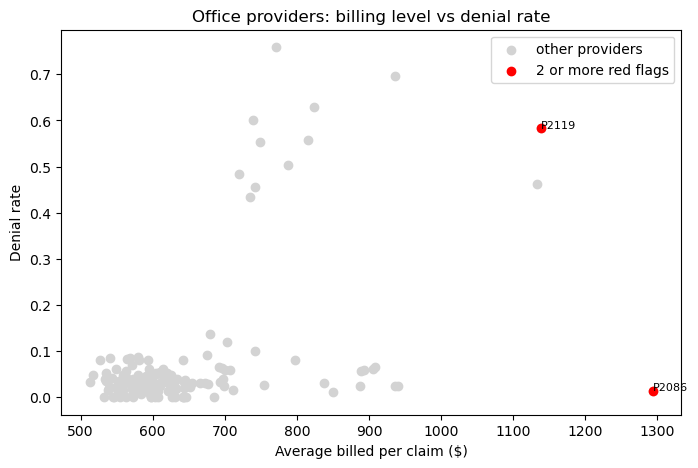

In [4]:
import matplotlib.pyplot as plt

office = summary[(summary.peer_group == "11 - Office") & eligible]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(office.avg_billed, office.denial_rate, c="lightgray", label="other providers")
hot = office[office.red_flags >= 2]
ax.scatter(hot.avg_billed, hot.denial_rate, c="red", label="2 or more red flags")
for pid, row in hot.iterrows():
    ax.annotate(pid, (row.avg_billed, row.denial_rate), fontsize=8)
ax.set_xlabel("Average billed per claim ($)")
ax.set_ylabel("Denial rate")
ax.set_title("Office providers: billing level vs denial rate")
ax.legend()
plt.show()

## Step 4: Deep dive into one provider

Change `SUSPECT` to investigate any other provider. We compare the provider with the **other providers in the same peer group**.

In [5]:
SUSPECT = "P2086"

group = summary.loc[SUSPECT, "peer_group"]
peer_ids = summary.index[(summary.peer_group == group) & (summary.index != SUSPECT)]
mine = main[main.provider_id == SUSPECT]
peers = main[main.provider_id.isin(peer_ids)]

def profile(d):
    return pd.Series({
        "claims": len(d),
        "avg billed per claim": d.total_billed.mean(),
        "avg allowed per claim": d.total_allowed.mean(),
        "denial rate": (d.claim_status == "Denied").mean(),
        "claims per member": len(d) / d.member_id.nunique(),
        "median days to submit": d.days_to_submit.median(),
        "avg processing days": d.processing_days.mean(),
    })

comparison = pd.DataFrame({SUSPECT: profile(mine), f"peers ({group})": profile(peers)})
comparison.round(2)

,P2086,peers (11 - Office)
claims,143.00,11105.00
avg billed per claim,1294.35,639.99
avg allowed per claim,615.39,290.20
denial rate,0.01,0.07
claims per member,1.08,2.27
median days to submit,3.00,5.00
avg processing days,10.33,8.49


### Which procedures drive the difference?

In [6]:
def line_profile(provider_ids):
    d = lines.merge(main[["claim_id", "provider_id"]], on="claim_id")
    d = d[d.provider_id.isin(provider_ids)]
    return d.groupby("procedure_code").agg(lines=("units", "size"), avg_units=("units", "mean"),
                                           avg_billed=("billed_amount", "mean"),
                                           avg_allowed=("allowed_amount", "mean"))

a = line_profile([SUSPECT])
b = line_profile(peer_ids)
procs = a.join(b, lsuffix="_provider", rsuffix="_peers", how="left")
procs["units_ratio"] = procs.avg_units_provider / procs.avg_units_peers
procs["billed_ratio"] = procs.avg_billed_provider / procs.avg_billed_peers
procs.sort_values("lines_provider", ascending=False).round(2).head(10)

,lines_provider,avg_units_provider,avg_billed_provider,avg_allowed_provider,lines_peers,avg_units_peers,avg_billed_peers,avg_allowed_peers,units_ratio,billed_ratio
procedure_code,,,,,,,,,,
97110,143,7.01,1009.76,480.65,779,3.01,431.81,190.78,2.33,2.34
97140,143,1.52,204.80,98.45,779,1.50,203.12,88.69,1.02,1.01
97161,24,1.00,475.45,216.20,122,1.00,480.72,209.13,1.00,0.99


In [7]:
# distribution of units on the procedure with the biggest gap
top_proc = procs.units_ratio.sort_values(ascending=False).index[0]
d = lines.merge(main[["claim_id", "provider_id"]], on="claim_id")
d = d[d.procedure_code == top_proc]
print("Procedure", top_proc, "- units per line (share of lines)")
print(pd.DataFrame({
    SUSPECT: d[d.provider_id == SUSPECT].units.value_counts(normalize=True).sort_index(),
    "peers": d[d.provider_id.isin(peer_ids)].units.value_counts(normalize=True).sort_index(),
}).round(3))

Procedure 97110 - units per line (share of lines)
       P2086  peers
units              
2        NaN  0.339
3        NaN  0.315
4        NaN  0.347
6      0.343    NaN
7      0.301    NaN
8      0.357    NaN


### Money at risk (estimate)

In [8]:
paid_lines = lines.merge(main[["claim_id", "provider_id", "claim_status"]], on="claim_id")
paid_lines = paid_lines[(paid_lines.claim_status == "Paid") & (paid_lines.paid_amount > 0)]

peer_median_units = (paid_lines[paid_lines.provider_id.isin(peer_ids)]
                     .groupby("procedure_code").units.median().rename("peer_median_units"))

x = paid_lines[paid_lines.provider_id == SUSPECT].join(peer_median_units, on="procedure_code")
x["excess_units"] = (x.units - x.peer_median_units).clip(lower=0)
x["excess_paid"] = x.excess_units * x.paid_amount / x.units
# only count procedures with a clear difference (units at least 1.5 times the peers)
clear = procs.index[procs.units_ratio >= 1.5]
x = x[x.procedure_code.isin(clear)]
excess = x.groupby("procedure_code").agg(lines=("units", "size"), excess_units=("excess_units", "sum"),
                                          excess_paid=("excess_paid", "sum"))
print("1) Estimated paid on excess units, by procedure:")
print(excess[excess.excess_paid > 0].round(0))
print("   TOTAL: $", round(x.excess_paid.sum()))

early = mine[mine.received_before_service]
print()
print(f"2) Claims received before the service date: {len(early)}")
print(f"   billed ${early.total_billed.sum():,.0f} | paid ${early.total_paid.sum():,.0f}")
early[["claim_id", "member_id", "service_from_date", "received_date", "total_billed", "total_paid", "claim_status"]].head(10)

1) Estimated paid on excess units, by procedure:
                lines  excess_units  excess_paid
procedure_code                                  
97110             131         531.0      31705.0
   TOTAL: $ 31705

2) Claims received before the service date: 30
   billed $40,991 | paid $15,427


,claim_id,member_id,service_from_date,received_date,total_billed,total_paid,claim_status
3346,CLM1052481,M104086,2025-12-14,2025-12-09,1909.67,671.70,Paid
3358,CLM1072164,M105591,2025-12-21,2025-12-20,1337.58,631.73,Paid
3363,CLM1006715,M100553,2025-12-28,2025-12-25,1466.26,457.36,Paid
3366,CLM1004050,M100339,2026-01-04,2025-12-31,1949.49,787.86,Paid
3372,CLM1071042,M105500,2026-01-04,2026-01-03,1602.55,0.00,Denied
3383,CLM1086072,M106692,2026-01-11,2026-01-07,1541.36,777.81,Paid
3385,CLM1025174,M101956,2026-01-11,2026-01-08,1428.55,590.79,Paid
3386,CLM1002109,M100183,2026-01-11,2026-01-09,1000.89,394.75,Paid
3387,CLM1102542,M107989,2026-01-11,2026-01-10,1428.13,650.47,Paid
3389,CLM1000927,M100075,2026-01-11,2026-01-10,1653.48,774.40,Paid


## Step 5: Providers with a very high denial rate

In [9]:
high_denial = summary[summary.flag_high_denial == 1].sort_values("denial_rate", ascending=False)
print("Providers with a very high denial rate:", len(high_denial))
d = real[real.provider_id.isin(high_denial.index) & (real.claim_status == "Denied")]
pivot = d.pivot_table(index="provider_id", columns="denial_code", values="claim_id", aggfunc="count", fill_value=0)
out = high_denial[["claims", "denial_rate", "avg_billed"]].join(pivot)
out.round(2)

Providers with a very high denial rate: 7


,claims,denial_rate,avg_billed,COD01,INF01,NCV01,OON01,TF01
provider_id,,,,,,,,
P2210,29,0.76,770.88,0,0,1,24,0
P2134,33,0.70,936.54,0,0,2,21,0
P2140,78,0.63,823.82,0,0,1,48,0
P2103,55,0.60,739.41,0,0,1,31,1
P2119,24,0.58,1138.94,0,1,0,13,0
P2144,70,0.56,815.21,1,0,3,35,0
P2006,85,0.55,748.97,2,1,2,42,0


## Step 6: Possible duplicate billing

In [10]:
dup_claims = real[real.duplicated(key, keep=False)].sort_values(key)
print("Claims in a possible duplicate set:", len(dup_claims))
print(dup_claims.provider_id.value_counts().to_string())
dup_claims[["provider_id", "member_id", "service_from_date", "primary_diagnosis", "claim_id",
            "total_billed", "total_paid", "claim_status"]].head(12)

Claims in a possible duplicate set: 28
provider_id
P2104    22
P2064     2
P2008     2
P2093     2


,provider_id,member_id,service_from_date,primary_diagnosis,claim_id,total_billed,total_paid,claim_status
10518,P2064,M100259,2025-12-15,J06.9,CLM1003124,579.11,250.89,Paid
10519,P2064,M100259,2025-12-15,J06.9,CLM1003126,552.31,188.67,Paid
873,P2104,M100936,2025-12-29,Z00.00,CLM1011714,1282.73,676.87,Paid
942,P2104,M100936,2025-12-29,Z00.00,CLM1103927,1090.91,707.39,Paid
874,P2104,M101356,2025-12-15,U07.1,CLM1017238,297.11,118.29,Paid
934,P2104,M101356,2025-12-15,U07.1,CLM1103869,338.56,121.64,Paid
943,P2104,M101821,2026-02-09,N18.30,CLM1023197,599.63,214.92,Paid
986,P2104,M101821,2026-02-09,N18.30,CLM1103892,563.95,0.00,Denied
11065,P2008,M102324,2026-01-07,Z00.00,CLM1029876,1143.30,708.84,Paid
11068,P2008,M102324,2026-01-07,Z00.00,CLM1029875,1363.69,667.11,Paid


## Step 7: Save the results

In [11]:
summary.round(4).to_csv(OUT / "provider_summary.csv")
ranked.round(4).to_csv(OUT / "flagged_providers.csv")
early.to_csv(OUT / f"{SUSPECT}_received_before_service.csv", index=False)
dup_claims.to_csv(OUT / "possible_duplicate_claims.csv", index=False)
try:
    with pd.ExcelWriter(OUT / "fraud_findings_draft.xlsx") as xl:
        ranked.round(4).to_excel(xl, sheet_name="flagged_providers")
        summary.round(4).to_excel(xl, sheet_name="provider_summary")
        dup_claims.to_excel(xl, sheet_name="possible_duplicates", index=False)
    print("Saved Excel file too.")
except ModuleNotFoundError:
    print("Excel file skipped (run: pip install openpyxl). CSV files were saved.")
print("Saved to", OUT.resolve())

Saved Excel file too.
Saved to C:\Users\munic\Desktop\Oriana Data Analytics Internship\Final Project\Dataset\fraud_outputs
